[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_rollq/BA_L5_rollq.ipynb)

# BA_L5_rollq: The rolling 5% quantile counts ranks, not depth

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Daily reference-adjusted deviations of USD Coin (USDC) and Dai (DAI) and the 5% quantile of the previous 90 days (the 5th lowest deviation), July 2022 - March 2024, around the Silicon Valley Bank (SVB) depeg of March 2023 (EODHD data).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## The rolling 5% quantile counts ranks, not depth

**Reference adjustment.** Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset ($B = 1$ for dollar tokens, EUR/USD for STASIS Euro (EURS), XAU/USD for Pax Gold (PAXG)). The reference-adjusted deviation, in basis points (bp, 0.01%), is
$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right). $$
Prices are put on a calendar of all days and filled from the past for at most 7 days; a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error and removed.

In a window of $n = 90$ days, $n\tau = 4.5$ for $\tau = 0.05$, so the 5% quantile that minimises the check loss is the 5th lowest observation.

**How to read the chart.** Thin lines: the daily deviation $d_t$ of USDC and DAI (bp). Step lines: the 5% quantile of the 90 days before day $t$. The dotted lines mark the days when the SVB weekend enters and leaves the window.

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


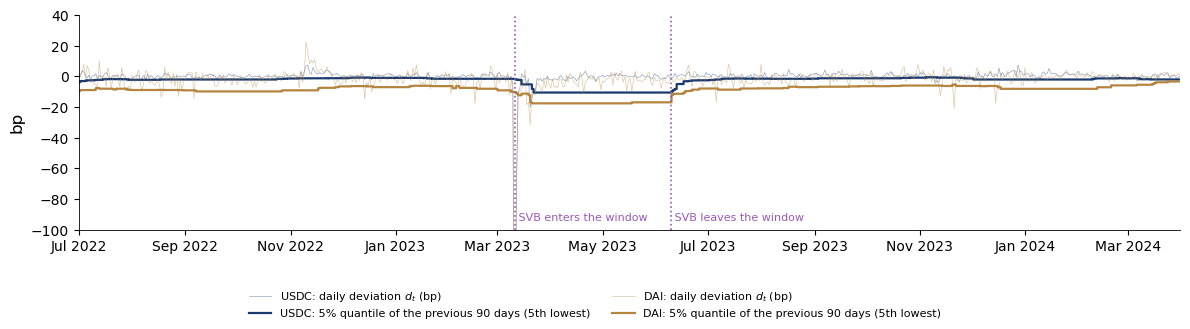

In [5]:
import matplotlib.dates
q05 = D.rolling(90).quantile(0.05, interpolation='lower').shift(1)        # 5th lowest of the 90 days before t
fig, ax = plt.subplots(figsize=(12, 3.3))
for c, col in [('USDC', BLUE), ('DAI', GOLD)]:
    ax.plot(D.index, D[c], color=col, lw=0.5, alpha=0.45, label=f'{c}: daily deviation $d_t$ (bp)')
    ax.step(q05.index, q05[c], color=col, lw=1.6, where='post', label=f'{c}: 5% quantile of the previous 90 days (5th lowest)')
for t_, lab in [('2023-03-11', 'SVB enters the window'), ('2023-06-10', 'SVB leaves the window')]:
    ax.axvline(pd.Timestamp(t_), color=ETH, ls=':', lw=1.2)
    ax.text(pd.Timestamp(t_), -95, ' ' + lab, fontsize=8, color=ETH, va='bottom')
ax.set_xlim(pd.Timestamp('2022-07-01'), pd.Timestamp('2024-03-31')); ax.set_ylim(-100, 40); ax.set_ylabel('bp')
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%b %Y'))
finish_fig(fig, 'ba_l5_rollq', 0.17, ncol=2)

## Key numbers

In [6]:
print('USDC daily deviations, 10-14 March 2023 (bp):', D['USDC'].loc['2023-03-10':'2023-03-14'].round(1).to_dict())
print('five lowest USDC deviations in the 90 days to 11 March 2023 (bp):', np.sort(D['USDC'].loc['2022-12-12':'2023-03-11'].values)[:5].round(2))
pd.Series({d_: q05.loc[d_, 'USDC'] for d_ in ['2023-03-11', '2023-03-12', '2023-03-15', '2023-03-22', '2023-06-09', '2023-06-13']},
          name='USDC: 5% quantile of the 90 days before (bp)').round(2).to_frame()

USDC daily deviations, 10-14 March 2023 (bp): {Timestamp('2023-03-10 00:00:00'): -5.2, Timestamp('2023-03-11 00:00:00'): -285.0, Timestamp('2023-03-12 00:00:00'): -79.3, Timestamp('2023-03-13 00:00:00'): -10.5, Timestamp('2023-03-14 00:00:00'): -8.2}
five lowest USDC deviations in the 90 days to 11 March 2023 (bp): [-285.     -5.21   -2.39   -2.25   -2.15]


,USDC: 5% quantile of the 90 days before (bp)
2023-03-11,-1.90
2023-03-12,-2.15
2023-03-15,-5.21
2023-03-22,-10.53
2023-06-09,-10.53
2023-06-13,-4.98


**How to read it:** when the $-285$ bp close of 11 March 2023 enters the window, the 5% quantile of USDC moves only from $-1.90$ to $-2.15$ bp. It reaches $-5.21$ bp on 15 March, when four SVB days are among the five lowest, stays at $-10.5$ bp from 22 March to 9 June and returns to $-5.0$ bp once the SVB days leave the window. The size of the lowest day never enters the estimate, only its rank.